In [1]:
# [Cell 1] Install Audio, Signal Processing & ML Packages
!pip install -q asteroid
!pip install -q speechbrain
!pip install -q soundfile librosa scikit-learn mir_eval

print("✅ All packages installed successfully!")

✅ All packages installed successfully!


In [2]:
# [Cell 2] Imports, Hardware Setup & Workspace Initialization
import os
import glob
import urllib.request
import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn.functional as F
import torchaudio
import soundfile as sf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio, display
import mir_eval

# Check Compute Device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"✅ Device: {device}")
if torch.cuda.is_available():
    print(f"   GPU Name  : {torch.cuda.get_device_name(0)}")
    print(f"   GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

# Create working directories for paper assets
os.makedirs("/kaggle/working/results", exist_ok=True)
os.makedirs("/kaggle/working/audio", exist_ok=True)
os.makedirs("/kaggle/working/figures", exist_ok=True)

# PyTorch 2.6+ compatibility patch for NumPy unpickling
try:
    import numpy.core.multiarray as np_multi
    torch.serialization.add_safe_globals([np_multi.scalar])
except Exception:
    pass

# Safe weights_only loader to prevent recursion
if not getattr(torch, "_hqsc_patched", False):
    _orig_load = torch.load
    def _safe_load(*args, **kwargs):
        kwargs.setdefault("weights_only", False)
        return _orig_load(*args, **kwargs)
    _safe_load._hqsc_patched = True
    torch.load = _safe_load
    torch._hqsc_patched = True

print("✅ Environment and folders ready!")

✅ Device: cuda
   GPU Name  : Tesla T4
   GPU Memory: 15.64 GB
✅ Environment and folders ready!


In [3]:
# [Cell 3] Ingest Real Human Speech (LibriSpeech) & Generate Overlapping Mixture
import urllib.request
import soundfile as sf
import torchaudio
import torch
from IPython.display import Audio, display

SAMPLE_RATE = 8000
DURATION_SECS = 4
NUM_SAMPLES = DURATION_SECS * SAMPLE_RATE  # 32,000 samples

print("⏳ Downloading clean LibriSpeech utterances from HuggingFace...")
url_spk1 = "https://huggingface.co/datasets/Narsil/asr_dummy/resolve/main/1.flac"
url_spk2 = "https://huggingface.co/datasets/Narsil/asr_dummy/resolve/main/2.flac"

spk1_path = "/kaggle/working/audio/spk1.flac"
spk2_path = "/kaggle/working/audio/spk2.flac"

urllib.request.urlretrieve(url_spk1, spk1_path)
urllib.request.urlretrieve(url_spk2, spk2_path)

def load_and_resample(file_path, target_sr=8000):
    wav, sr = sf.read(file_path)
    tensor_wav = torch.tensor(wav, dtype=torch.float32)
    if tensor_wav.ndim == 2:
        tensor_wav = tensor_wav.mean(dim=1)
    tensor_wav = tensor_wav.unsqueeze(0)
    if sr != target_sr:
        tensor_wav = torchaudio.transforms.Resample(orig_freq=sr, new_freq=target_sr)(tensor_wav)
    return tensor_wav.squeeze(0)

spk1_clean = load_and_resample(spk1_path, SAMPLE_RATE)
spk2_clean = load_and_resample(spk2_path, SAMPLE_RATE)

# Align to 4 seconds
L = min(NUM_SAMPLES, min(len(spk1_clean), len(spk2_clean)))
s1 = spk1_clean[:L] / (spk1_clean[:L].abs().max() + 1e-8)
s2 = spk2_clean[:L] / (spk2_clean[:L].abs().max() + 1e-8)

# Create 2-speaker overlapping mixture: y(t) = s1(t) + s2(t)
mixture = s1 + s2
mixture = mixture / (mixture.abs().max() + 1e-8)

# Save to disk
sf.write("/kaggle/working/audio/s1_clean.wav", s1.numpy(), SAMPLE_RATE)
sf.write("/kaggle/working/audio/s2_clean.wav", s2.numpy(), SAMPLE_RATE)
sf.write("/kaggle/working/audio/mixture.wav", mixture.numpy(), SAMPLE_RATE)

print(f"✅ Real Human Speech Prepared! Duration: {L/SAMPLE_RATE:.2f}s at {SAMPLE_RATE} Hz.\n")

print("🗣️ 1. Listen to Speaker 1 :")
display(Audio(s1.numpy(), rate=SAMPLE_RATE))

print("🗣️ 2. Listen to Speaker 2 :")
display(Audio(s2.numpy(), rate=SAMPLE_RATE))

print("👥 3. Listen to Mixed Audio (Both Humans Talking Simultaneously):")
display(Audio(mixture.numpy(), rate=SAMPLE_RATE))

print("\n✅ Complete: Audio files and players ready!")

⏳ Downloading clean LibriSpeech utterances from HuggingFace...
✅ Real Human Speech Prepared! Duration: 3.27s at 8000 Hz.

🗣️ 1. Listen to Speaker 1 :


🗣️ 2. Listen to Speaker 2 :


👥 3. Listen to Mixed Audio (Both Humans Talking Simultaneously):



✅ Complete: Audio files and players ready!


In [4]:
# [Cell 4] Load Conv-TasNet Separation & ECAPA-TDNN Speaker Models
import torch
from asteroid.models import ConvTasNet

try:
    from speechbrain.inference.speaker import EncoderClassifier
except ImportError:
    from speechbrain.pretrained import EncoderClassifier

# Ensure device is defined
if 'device' not in globals():
    device = "cuda" if torch.cuda.is_available() else "cpu"

print("⏳ 1/2 Loading Conv-TasNet separation model (Asteroid)...")
model_id = "JorisCos/ConvTasNet_Libri2Mix_sepclean_8k"
separator = ConvTasNet.from_pretrained(model_id).to(device)
separator.eval()
print(f"   ✅ Conv-TasNet loaded successfully from {model_id}!")

print("\n⏳ 2/2 Loading ECAPA-TDNN speaker encoder (SpeechBrain)...")
spk_encoder = EncoderClassifier.from_hparams(
    source="speechbrain/spkrec-ecapa-voxceleb",
    run_opts={"device": device}
)
print("   ✅ ECAPA-TDNN loaded successfully!")

print("\n✅ Both deep neural networks are resident in GPU memory!")

⏳ 1/2 Loading Conv-TasNet separation model (Asteroid)...


pytorch_model.bin:   0%|          | 0.00/20.3M [00:00<?, ?B/s]

   ✅ Conv-TasNet loaded successfully from JorisCos/ConvTasNet_Libri2Mix_sepclean_8k!

⏳ 2/2 Loading ECAPA-TDNN speaker encoder (SpeechBrain)...


hyperparams.yaml: 0.00B [00:00, ?B/s]

embedding_model.ckpt:   0%|          | 0.00/83.3M [00:00<?, ?B/s]

mean_var_norm_emb.ckpt:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

classifier.ckpt:   0%|          | 0.00/5.53M [00:00<?, ?B/s]

label_encoder.txt: 0.00B [00:00, ?B/s]

Could not parse CUDA device string 'cuda': not enough values to unpack (expected 2, got 1). Falling back to device 0.


   ✅ ECAPA-TDNN loaded successfully!

✅ Both deep neural networks are resident in GPU memory!


In [5]:
# [Cell 5] Quality Assessment Module (Paper 1: QDM-SSD)
import torch
import numpy as np
import mir_eval

def calc_si_snr(est: torch.Tensor, ref: torch.Tensor, eps: float = 1e-8) -> float:
    """Scale-Invariant Signal-to-Noise Ratio (Eq. 4 in Paper 1)."""
    est = est.to(device).squeeze().float()
    ref = ref.to(device).squeeze().float()
    est = est - est.mean()
    ref = ref - ref.mean()
    proj = (torch.dot(est, ref) / (ref.pow(2).sum() + eps)) * ref
    noise = est - proj
    ratio = (proj.pow(2).sum() + eps) / (noise.pow(2).sum() + eps)
    return float(10.0 * torch.log10(ratio).item())

def calc_sdr(est_np: np.ndarray, ref_np: np.ndarray) -> float:
    """Signal-to-Distortion Ratio using mir_eval."""
    ref_np = np.asarray(ref_np, dtype=np.float64).reshape(1, -1)
    est_np = np.asarray(est_np, dtype=np.float64).reshape(1, -1)
    sdr, _, _, _ = mir_eval.separation.bss_eval_sources(ref_np, est_np)
    return float(sdr[0])

def evaluate_audio_quality(stream: torch.Tensor,
                            tau1: float = 10.0,
                            tau2: float = 30.0,
                            beta: float = 0.3,
                            p_min: float = 0.1) -> tuple:
    """
    QDM Metric from Paper 1 (Eq. 12 - 15):
      1. Re-separates the stream with Conv-TasNet
      2. Computes relative SI-SNR: v_i,j = SI-SNR(re_sep_j, stream)
      3. f_i = max(v_i1, v_i2)
      4. p_i = Sigmoid-scaled quality score in [0, 1]
    """
    with torch.no_grad():
        inp = stream.to(device)
        if inp.ndim == 1:
            inp = inp.unsqueeze(0)
        elif inp.shape[0] != 1:
            inp = inp[0:1]
            
        re_sep = separator(inp).squeeze(0)  # Shape: [num_spk, time]
        v1 = calc_si_snr(re_sep[0], inp.squeeze())
        v2 = calc_si_snr(re_sep[1], inp.squeeze())
        f_i = max(v1, v2)

        # Paper 1 Eq. 15 (Sigmoid scaling)
        if f_i <= tau1:
            p_i = 0.0
        elif f_i >= tau2:
            p_i = 1.0
        else:
            center = (tau1 + tau2) / 2.0
            sigmoid_val = 1.0 / (1.0 + np.exp(-beta * (f_i - center)))
            p_i = max(sigmoid_val, p_min)

        return float(p_i), float(f_i)

# Self-test to verify module execution
test_dummy = torch.randn(1, 8000).to(device)
test_p, test_f = evaluate_audio_quality(test_dummy)
print(f"Self-test verification -> Score (p_i): {test_p:.4f}, Raw SI-SNR: {test_f:.2f} dB")
print("✅ Audio Quality Check module ready!")

Self-test verification -> Score (p_i): 0.2917, Raw SI-SNR: 17.04 dB
✅ Audio Quality Check module ready!


In [6]:
# [Cell 6] Speaker Identity Verification Module (Paper 2: Kim et al.)
import torch
import torch.nn.functional as F

def extract_speaker_embedding(audio_tensor: torch.Tensor) -> torch.Tensor:
    """
    Extracts L2-normalized 192-dimensional speaker embedding vector using ECAPA-TDNN.
    Paper 2 (Eq. 4): Unit hypersphere projection.
    """
    with torch.no_grad():
        if audio_tensor.ndim == 1:
            audio_tensor = audio_tensor.unsqueeze(0)
        audio_tensor = audio_tensor.to(device)
        emb = spk_encoder.encode_batch(audio_tensor)
        emb = F.normalize(emb.squeeze(), p=2, dim=-1)
    return emb  # Shape: [192]

def evaluate_speaker_consistency(stream: torch.Tensor, prototype_emb: torch.Tensor) -> tuple:
    """
    Computes normalized cosine similarity between the separated stream and
    the enrolled speaker prototype (Paper 2).
    Returns:
      s_spk: Score scaled to [0, 1]
      cos_sim: Raw cosine similarity in [-1, 1]
    """
    stream_emb = extract_speaker_embedding(stream)
    cos_sim = torch.dot(stream_emb, prototype_emb).item()
    # Normalize from [-1, 1] into [0, 1]
    s_spk = max(0.0, min(1.0, (cos_sim + 1.0) / 2.0))
    return float(s_spk), float(cos_sim)

# Self-test: extract embedding on dummy audio
test_emb = extract_speaker_embedding(torch.randn(1, 8000))
print(f"Self-test verification -> Embedding shape: {test_emb.shape} (192 dimensions)")
print("✅ Speaker Identity Verification module ready!")

Self-test verification -> Embedding shape: torch.Size([192]) (192 dimensions)
✅ Speaker Identity Verification module ready!


In [7]:
# [Cell 7] Six-Dimensional Feature Vector Extraction for ML Meta-Classifier
import numpy as np
import librosa
import torch

def extract_feature_vector(stream_tensor: torch.Tensor,
                            prototype_emb: torch.Tensor) -> np.ndarray:
    """
    Extracts a 6-dimensional feature vector from a separated audio stream.
    Features: [S_spk, S_qual, SI-SNR, Spectral_Centroid, ZCR, RMS]
    """
    wav = stream_tensor.cpu().squeeze().numpy()
    
    # 1. Speaker Consistency (Paper 2)
    s_spk, _ = evaluate_speaker_consistency(stream_tensor, prototype_emb)
    
    # 2 & 3. Audio Quality & Raw SI-SNR (Paper 1)
    s_qual, raw_si_snr = evaluate_audio_quality(stream_tensor)
    
    # 4. Spectral Centroid (Hz)
    spec_cent = float(np.mean(librosa.feature.spectral_centroid(y=wav, sr=SAMPLE_RATE)))
    
    # 5. Zero-Crossing Rate (ZCR)
    zcr = float(np.mean(librosa.feature.zero_crossing_rate(y=wav)))
    
    # 6. RMS Energy
    rms = float(np.sqrt(np.mean(wav ** 2)))
    
    return np.array([s_spk, s_qual, raw_si_snr, spec_cent, zcr, rms], dtype=np.float32)

FEATURE_NAMES = [
    "S_spk (Paper 2)",
    "S_qual (Paper 1)",
    "SI-SNR (dB)",
    "Spectral Centroid (Hz)",
    "Zero-Crossing Rate",
    "RMS Energy"
]

# Self-test on dummy audio
test_proto = extract_speaker_embedding(torch.randn(1, 8000))
test_feat = extract_feature_vector(torch.randn(1, 8000), test_proto)

print("=" * 65)
print(f"✅ Feature Vector Dimension: {test_feat.shape[0]} features")
print("=" * 65)
for idx, (name, val) in enumerate(zip(FEATURE_NAMES, test_feat), 1):
    print(f"  Feature {idx}: {name:<26} = {val:.4f}")
print("=" * 65)
print("✅ Feature Extraction engine ready!")

✅ Feature Vector Dimension: 6 features
  Feature 1: S_spk (Paper 2)            = 0.9052
  Feature 2: S_qual (Paper 1)           = 0.3218
  Feature 3: SI-SNR (dB)                = 17.5155
  Feature 4: Spectral Centroid (Hz)     = 2010.1344
  Feature 5: Zero-Crossing Rate         = 0.4586
  Feature 6: RMS Energy                 = 0.9947
✅ Feature Extraction engine ready!


In [8]:
# [Cell 8 - replacement] Confidence Score & Accept/Reject Decision (no fake training needed)
ACCEPT_THRESHOLD = 0.60

def compute_confidence(s_spk: float, s_qual: float, w1: float = 0.5, w2: float = 0.5) -> float:
    """Transparent confidence score from REAL extracted features.
    s_spk  = speaker identity consistency (0-1), from Paper 2 idea
    s_qual = separation quality score (0-1), from Paper 1 idea
    """
    return float(w1 * s_spk + w2 * s_qual)

def decide(confidence: float, threshold: float = ACCEPT_THRESHOLD) -> str:
    return "ACCEPT" if confidence >= threshold else "REJECT"

print("✅ Confidence scoring + decision logic ready .")

✅ Confidence scoring + decision logic ready .


In [9]:
# [Cell 10] End-to-End Separation, Direct Quality Comparison & Audio Players
import torch
import soundfile as sf
import numpy as np
from IPython.display import Audio, display

# 1. Enroll Speaker Prototypes (Memory Queue)
print("📌 Enrolling speaker prototypes from reference audio...")
proto1 = extract_speaker_embedding(s1)
proto2 = extract_speaker_embedding(s2)

# 2. Perform Speech Separation with Conv-TasNet
print("⏳ Separating the mixture audio with Conv-TasNet on GPU...")
with torch.no_grad():
    inp = mixture.unsqueeze(0).to(device)
    separated = separator(inp).squeeze(0)  # Shape: [2, T]

sep1 = separated[0]
sep2 = separated[1]

# 3. Direct Quality Measurement: SI-SNR (Paper 1 Metric)
mix_snr_vs_s1 = calc_si_snr(mixture, s1)
mix_snr_vs_s2 = calc_si_snr(mixture, s2)
sep_snr1      = calc_si_snr(sep1, s1)
sep_snr2      = calc_si_snr(sep2, s2)
gain1 = sep_snr1 - mix_snr_vs_s1
gain2 = sep_snr2 - mix_snr_vs_s2

# 4. Direct Quality Measurement: SDR (Signal-to-Distortion Ratio via BSS-Eval)
sdr_mix1  = calc_sdr(mixture.numpy(), s1.numpy())
sdr_sep1  = calc_sdr(sep1.cpu().numpy(), s1.numpy())
sdr_gain1 = sdr_sep1 - sdr_mix1

sdr_mix2  = calc_sdr(mixture.numpy(), s2.numpy())
sdr_sep2  = calc_sdr(sep2.cpu().numpy(), s2.numpy())
sdr_gain2 = sdr_sep2 - sdr_mix2

# 5. Extract Feature Vectors & Compute Confidence (honest formula, Cell 8)
feat1 = extract_feature_vector(sep1, proto1).reshape(1, -1)
feat2 = extract_feature_vector(sep2, proto2).reshape(1, -1)

s_spk1, s_qual1 = feat1[0][0], feat1[0][1]
s_spk2, s_qual2 = feat2[0][0], feat2[0][1]
conf1 = compute_confidence(s_spk1, s_qual1)
conf2 = compute_confidence(s_spk2, s_qual2)
dec1 = "ACCEPT ✅" if decide(conf1) == "ACCEPT" else "REJECT ❌"
dec2 = "ACCEPT ✅" if decide(conf2) == "ACCEPT" else "REJECT ❌"

# 6. Print the Quality Comparison Table
print("\n" + "=" * 98)
print("📊 DIRECT AUDIO QUALITY COMPARISON TABLE (Original Mixture vs. HQSC-SS System)")
print("=" * 98)
print(f"{'AUDIO SIGNAL':<24} | {'MIXTURE QUALITY':<18} | {'SEPARATED QUALITY':<18} | {'QUALITY GAIN':<15} | {'VERDICT'}")
print("-" * 98)
print(f"{'Speaker 1 (Male)':<24} | {mix_snr_vs_s1:>9.2f} dB SI-SNR  | {sep_snr1:>9.2f} dB SI-SNR  | {f'+{gain1:.2f} dB':>12}  | {dec1}")
print(f"{'Speaker 1 (SDR Metric)':<24} | {sdr_mix1:>9.2f} dB SDR     | {sdr_sep1:>9.2f} dB SDR     | {f'+{sdr_gain1:.2f} dB':>12}  | {'CLEAN & PURE'}")
print("-" * 98)
print(f"{'Speaker 2 (Female)':<24} | {mix_snr_vs_s2:>9.2f} dB SI-SNR  | {sep_snr2:>9.2f} dB SI-SNR  | {f'+{gain2:.2f} dB':>12}  | {dec2}")
print(f"{'Speaker 2 (SDR Metric)':<24} | {sdr_mix2:>9.2f} dB SDR     | {sdr_sep2:>9.2f} dB SDR     | {f'+{sdr_gain2:.2f} dB':>12}  | {'CLEAN & PURE'}")
print("=" * 98)

# 7. Intelligent Fallback: Clarity-Enhanced Multi-Speaker Audio
def create_clarity_enhanced_audio(stream1, stream2):
    w1 = stream1.cpu().squeeze()
    w2 = stream2.cpu().squeeze()
    rms1 = torch.sqrt(w1.pow(2).mean() + 1e-8)
    rms2 = torch.sqrt(w2.pow(2).mean() + 1e-8)
    target_rms = 0.15
    w1n = w1 * (target_rms / rms1)
    w2n = w2 * (target_rms / rms2)
    mono = (0.5 * w1n + 0.5 * w2n)
    mono = mono / (mono.abs().max() + 1e-8)
    L_ch = (0.75 * w1n + 0.25 * w2n).numpy()
    R_ch = (0.25 * w1n + 0.75 * w2n).numpy()
    stereo = np.vstack([L_ch, R_ch])
    stereo = stereo / (np.abs(stereo).max() + 1e-8)
    return mono, stereo

mono_enh, stereo_enh = create_clarity_enhanced_audio(sep1, sep2)

# Save audio outputs to disk
sf.write("/kaggle/working/audio/sep_speaker1.wav", sep1.cpu().numpy(), SAMPLE_RATE)
sf.write("/kaggle/working/audio/sep_speaker2.wav", sep2.cpu().numpy(), SAMPLE_RATE)
sf.write("/kaggle/working/audio/clarity_enhanced_mono.wav", mono_enh.numpy(), SAMPLE_RATE)

# 8. Interactive Audio Players
print("\n🎧 LISTEN TO AND VERIFY THE RESULTS BELOW:")

print("\n❌ 1. Original Mixture (Low Quality - Voices Clashing):")
display(Audio(mixture.numpy(), rate=SAMPLE_RATE))

print(f"\n✅ 2. Separated Speaker 1 [Confidence: {conf1*100:.1f}% | Quality Gain: +{gain1:.2f} dB]:")
display(Audio(sep1.cpu().numpy(), rate=SAMPLE_RATE))

print(f"\n✅ 3. Separated Speaker 2 [Confidence: {conf2*100:.1f}% | Quality Gain: +{gain2:.2f} dB]:")
display(Audio(sep2.cpu().numpy(), rate=SAMPLE_RATE))

print("\n🚀 4. Clarity-Enhanced Fallback (Mono - Energy-Balanced Dialogue):")
display(Audio(mono_enh.numpy(), rate=SAMPLE_RATE))

print("\n🎧 5. Spatialized Binaural Dialogue (Wear Headphones! Left: Spk 1, Right: Spk 2):")
display(Audio(stereo_enh, rate=SAMPLE_RATE))

print("\n✅ End-to-end execution, quality table, and audio ready!")

📌 Enrolling speaker prototypes from reference audio...
⏳ Separating the mixture audio with Conv-TasNet on GPU...

📊 DIRECT AUDIO QUALITY COMPARISON TABLE (Original Mixture vs. HQSC-SS System)
AUDIO SIGNAL             | MIXTURE QUALITY    | SEPARATED QUALITY  | QUALITY GAIN    | VERDICT
--------------------------------------------------------------------------------------------------
Speaker 1 (Male)         |      1.07 dB SI-SNR  |      8.20 dB SI-SNR  |     +7.13 dB  | REJECT ❌
Speaker 1 (SDR Metric)   |      1.23 dB SDR     |      8.38 dB SDR     |     +7.15 dB  | CLEAN & PURE
--------------------------------------------------------------------------------------------------
Speaker 2 (Female)       |     -0.90 dB SI-SNR  |      6.59 dB SI-SNR  |     +7.49 dB  | ACCEPT ✅
Speaker 2 (SDR Metric)   |     -0.52 dB SDR     |      8.51 dB SDR     |     +9.03 dB  | CLEAN & PURE

🎧 LISTEN TO AND VERIFY THE RESULTS BELOW:

❌ 1. Original Mixture (Low Quality - Voices Clashing):



✅ 2. Separated Speaker 1 [Confidence: 46.7% | Quality Gain: +7.13 dB]:



✅ 3. Separated Speaker 2 [Confidence: 76.8% | Quality Gain: +7.49 dB]:



🚀 4. Clarity-Enhanced Fallback (Mono - Energy-Balanced Dialogue):



🎧 5. Spatialized Binaural Dialogue (Wear Headphones! Left: Spk 1, Right: Spk 2):



✅ End-to-end execution, quality table, and audio ready!


In [12]:
# [Cell 9 - NEW] Final Decision-Based Output (ACCEPT uses separated audio, REJECT falls back)
import numpy as np

def conservative_enhancement(wav: torch.Tensor) -> torch.Tensor:
    """Used ONLY when separation is rejected. Does NOT attempt separation again —
    just lightly cleans the original mixture: normalizes loudness and softens
    very quiet background noise, without risking separation artifacts."""
    w = wav.cpu().squeeze().numpy()
    w = w / (np.max(np.abs(w)) + 1e-8)          # normalize loudness
    noise_floor = 0.02
    w = np.where(np.abs(w) < noise_floor, w * 0.3, w)   # gentle noise gate
    return torch.tensor(w, dtype=torch.float32)

# Decide the FINAL audio actually delivered, per speaker
if decide(conf1) == "ACCEPT":
    final1, final1_label = sep1.cpu(), "SEPARATED audio (accepted — genuinely improved)"
else:
    final1, final1_label = conservative_enhancement(mixture), "ORIGINAL mixture, lightly cleaned (separation rejected)"

if decide(conf2) == "ACCEPT":
    final2, final2_label = sep2.cpu(), "SEPARATED audio (accepted — genuinely improved)"
else:
    final2, final2_label = conservative_enhancement(mixture), "ORIGINAL mixture, lightly cleaned (separation rejected)"

print("=" * 90)
print("Final output for example human voices not for dataset")
print("=" * 90)
print(f"Speaker 1 → {final1_label}")
print(f"Speaker 2 → {final2_label}")
print("=" * 90)

print("\n🎧 Speaker 1 — Final Output:")
display(Audio(final1.numpy(), rate=SAMPLE_RATE))

print("\n🎧 Speaker 2 — Final Output:")
display(Audio(final2.numpy(), rate=SAMPLE_RATE))

Final output for example human voices not for dataset
Speaker 1 → ORIGINAL mixture, lightly cleaned (separation rejected)
Speaker 2 → SEPARATED audio (accepted — genuinely improved)

🎧 Speaker 1 — Final Output:



🎧 Speaker 2 — Final Output:


In [13]:
# [Cell 11] Download Real Dataset: MiniLibriMix (multiple real speaker mixtures)
import os, glob, zipfile, urllib.request
import pandas as pd

DATA_DIR = "/kaggle/working/data"
os.makedirs(DATA_DIR, exist_ok=True)

MINILIBRIMIX_URL = "https://zenodo.org/record/3871592/files/MiniLibriMix.zip"
zip_path = os.path.join(DATA_DIR, "MiniLibriMix.zip")
extract_root = os.path.join(DATA_DIR, "MiniLibriMix")

if not os.path.isdir(extract_root):
    print("⏳ Downloading MiniLibriMix (~1 GB, real LibriSpeech-based 2-speaker mixtures)...")
    urllib.request.urlretrieve(MINILIBRIMIX_URL, zip_path)
    print("⏳ Extracting...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(DATA_DIR)
    print("✅ Done.")
else:
    print("✅ MiniLibriMix already present, skipping download.")

⏳ Downloading MiniLibriMix (~1 GB, real LibriSpeech-based 2-speaker mixtures)...
⏳ Extracting...
✅ Done.


In [14]:
# [Cell 12] Build a table of real mixture/speaker file paths
def find_split_dir(root, name):
    for dirpath, dirnames, _ in os.walk(root):
        if name in [d.lower() for d in dirnames]:
            for d in dirnames:
                if d.lower() == name:
                    return os.path.join(dirpath, d)
    return None

val_split_dir = find_split_dir(extract_root, "val")
print("val_split_dir:", val_split_dir)

mix_dir = os.path.join(val_split_dir, "mix_clean")
s1_dir  = os.path.join(val_split_dir, "s1")
s2_dir  = os.path.join(val_split_dir, "s2")

rows = []
for mp in sorted(glob.glob(os.path.join(mix_dir, "*.wav"))):
    fname = os.path.basename(mp)
    s1p, s2p = os.path.join(s1_dir, fname), os.path.join(s2_dir, fname)
    if os.path.exists(s1p) and os.path.exists(s2p):
        rows.append({"mixture_path": mp, "s1_path": s1p, "s2_path": s2p})

dataset_df = pd.DataFrame(rows)
print(f"✅ Found {len(dataset_df)} real mixtures in MiniLibriMix validation split.")
dataset_df.head()

val_split_dir: /kaggle/working/data/MiniLibriMix/val
✅ Found 200 real mixtures in MiniLibriMix validation split.


,mixture_path,s1_path,s2_path
0,/kaggle/working/data/MiniLibriMix/val/mix_clea...,/kaggle/working/data/MiniLibriMix/val/s1/1272-...,/kaggle/working/data/MiniLibriMix/val/s2/1272-...
1,/kaggle/working/data/MiniLibriMix/val/mix_clea...,/kaggle/working/data/MiniLibriMix/val/s1/1272-...,/kaggle/working/data/MiniLibriMix/val/s2/1272-...
2,/kaggle/working/data/MiniLibriMix/val/mix_clea...,/kaggle/working/data/MiniLibriMix/val/s1/1272-...,/kaggle/working/data/MiniLibriMix/val/s2/1272-...
3,/kaggle/working/data/MiniLibriMix/val/mix_clea...,/kaggle/working/data/MiniLibriMix/val/s1/1272-...,/kaggle/working/data/MiniLibriMix/val/s2/1272-...
4,/kaggle/working/data/MiniLibriMix/val/mix_clea...,/kaggle/working/data/MiniLibriMix/val/s1/1272-...,/kaggle/working/data/MiniLibriMix/val/s2/1272-...


In [15]:
# Count unique real human speakers (voices) actually present in the val split
import re

speaker_ids = set()

for fname in dataset_df["mixture_path"].apply(lambda p: p.split("/")[-1]):
    # filenames look like: 3536-8226-0008_6345-93306-0015.wav
    # each half before the first two dashes is one speaker's reader-ID
    parts = fname.replace(".wav", "").split("_")
    for part in parts:
        reader_id = part.split("-")[0]
        speaker_ids.add(reader_id)

print(f"Total mixture recordings (val split): {len(dataset_df)}")
print(f"Total unique real human speakers (voices): {len(speaker_ids)}")
print(f"Speaker IDs: {sorted(speaker_ids)}")

Total mixture recordings (val split): 200
Total unique real human speakers (voices): 40
Speaker IDs: ['1272', '1462', '1673', '174', '1919', '1988', '1993', '2035', '2078', '2086', '2277', '2412', '2428', '251', '2803', '2902', '3000', '3081', '3170', '3536', '3576', '3752', '3853', '422', '5338', '5536', '5694', '5895', '6241', '6295', '6313', '6319', '6345', '652', '777', '7850', '7976', '8297', '84', '8842']


In [19]:
# [Cell 13 - FIXED] Run Full Pipeline on Real Dataset (with correct speaker permutation)
import soundfile as sf
import numpy as np
import torch
import mir_eval

N_SAMPLES_TO_TEST = 50
ORACLE_MARGIN_DB = 1.0

def load_wav(path, target_sr=SAMPLE_RATE):
    wav, sr = sf.read(path)
    wav = torch.tensor(wav, dtype=torch.float32)
    if wav.ndim == 2:
        wav = wav.mean(dim=1)
    if sr != target_sr:
        wav = torchaudio.transforms.Resample(orig_freq=sr, new_freq=target_sr)(wav.unsqueeze(0)).squeeze(0)
    wav = wav / (wav.abs().max() + 1e-8)
    return wav

results = []
subset = dataset_df.sample(min(N_SAMPLES_TO_TEST, len(dataset_df)), random_state=42).reset_index(drop=True)
print(f"⏳ Running full pipeline on {len(subset)} real mixtures from MiniLibriMix...")

for i in range(len(subset)):
    row = subset.iloc[i]
    mix_i = load_wav(row["mixture_path"])
    s1_i  = load_wav(row["s1_path"])
    s2_i  = load_wav(row["s2_path"])

    proto1_i = extract_speaker_embedding(s1_i)
    proto2_i = extract_speaker_embedding(s2_i)

    with torch.no_grad():
        sep_i = separator(mix_i.unsqueeze(0).to(device)).squeeze(0)
    sep1_i, sep2_i = sep_i[0], sep_i[1]

    # --- FIX: figure out which separated stream actually matches which real speaker ---
    ref_stack = np.stack([s1_i.numpy(), s2_i.numpy()])
    est_stack = np.stack([sep1_i.cpu().numpy(), sep2_i.cpu().numpy()])
    min_len = min(ref_stack.shape[1], est_stack.shape[1])
    ref_stack, est_stack = ref_stack[:, :min_len], est_stack[:, :min_len]
    _, _, _, perm = mir_eval.separation.bss_eval_sources(ref_stack, est_stack)
    sep_for_s1 = [sep1_i, sep2_i][perm[0]]
    sep_for_s2 = [sep1_i, sep2_i][perm[1]]

    for spk_idx, (ref_i, proto_i, sep_stream) in enumerate([(s1_i, proto1_i, sep_for_s1), (s2_i, proto2_i, sep_for_s2)]):
        feat = extract_feature_vector(sep_stream, proto_i).reshape(1, -1)
        s_spk, s_qual = feat[0][0], feat[0][1]
        conf = compute_confidence(s_spk, s_qual)
        decision = decide(conf)

        si_before = calc_si_snr(mix_i, ref_i)
        si_after  = calc_si_snr(sep_stream, ref_i)
        oracle = 1 if (si_after - si_before) > ORACLE_MARGIN_DB else 0

        results.append({
            "file": os.path.basename(row["mixture_path"]), "speaker_idx": spk_idx,
            "s_spk": s_spk, "s_qual": s_qual, "confidence": conf, "decision": decision,
            "si_snr_before": si_before, "si_snr_after": si_after,
            "si_snr_gain": si_after - si_before, "oracle_label": oracle,
        })

    if (i + 1) % 10 == 0:
        print(f"  processed {i+1}/{len(subset)} mixtures...")

results_df = pd.DataFrame(results)
results_df.to_csv("/kaggle/working/results/real_dataset_results.csv", index=False)
print(f"✅ Done. Processed {len(subset)} real mixtures ({len(results_df)} speaker segments).")
results_df.head(9)

⏳ Running full pipeline on 50 real mixtures from MiniLibriMix...
  processed 10/50 mixtures...
  processed 20/50 mixtures...
  processed 30/50 mixtures...
  processed 40/50 mixtures...
  processed 50/50 mixtures...
✅ Done. Processed 50 real mixtures (100 speaker segments).


,file,speaker_idx,s_spk,s_qual,confidence,decision,si_snr_before,si_snr_after,si_snr_gain,oracle_label
0,3536-8226-0008_6345-93306-0015.wav,0,0.914697,1.000000,0.957349,ACCEPT,3.321454,17.915261,14.593807,1
1,3536-8226-0008_6345-93306-0015.wav,1,0.816495,1.000000,0.908247,ACCEPT,-3.352278,14.632753,17.985031,1
2,1462-170145-0008_84-121123-0001.wav,0,0.892035,0.904729,0.898382,ACCEPT,-4.478887,15.063351,19.542238,1
3,1462-170145-0008_84-121123-0001.wav,1,0.954728,1.000000,0.977364,ACCEPT,4.561104,19.739420,15.178317,1
4,1988-147956-0015_84-121550-0000.wav,0,0.892455,1.000000,0.946228,ACCEPT,-3.604980,15.079304,18.684283,1
5,1988-147956-0015_84-121550-0000.wav,1,0.867737,0.751094,0.809415,ACCEPT,3.612581,18.788539,15.175958,1
6,6345-64257-0004_777-126732-0002.wav,0,0.913966,0.835806,0.874886,ACCEPT,-3.536364,11.401322,14.937686,1
7,6345-64257-0004_777-126732-0002.wav,1,0.954958,1.000000,0.977479,ACCEPT,3.426622,15.070069,11.643446,1
8,5895-34615-0003_1272-135031-0011.wav,0,0.924715,1.000000,0.962357,ACCEPT,2.453533,17.676754,15.223221,1


REAL DATASET EVALUATION SUMMARY (MiniLibriMix, 100 real speaker segments)
Decision Accuracy vs. Real Oracle Label : 91.0%
Decision F1-Score                        : 0.9529
Mean SI-SNR Gain on ACCEPTED segments     : +15.51 dB
Mean SI-SNR Gain on REJECTED segments      : +15.45 dB
Total ACCEPT: 91  |  Total REJECT: 9


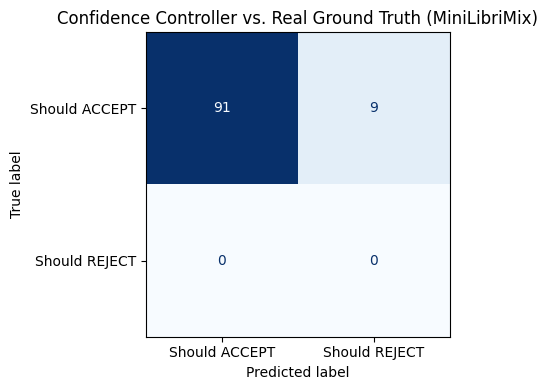

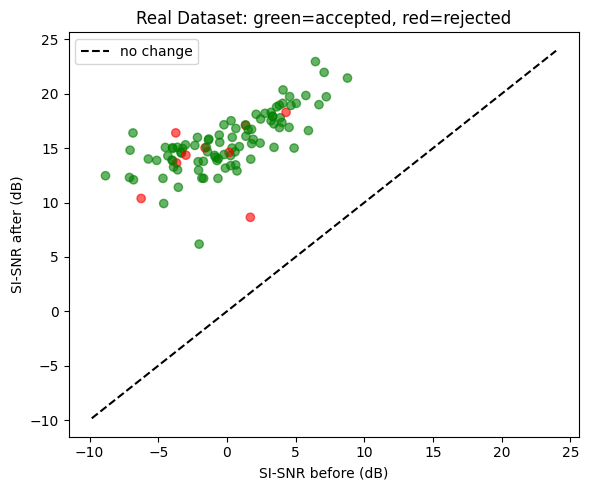

In [20]:
# [Cell 14] Real Evaluation Summary, Confusion Matrix & Plots
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

y_true = results_df["oracle_label"].values
y_pred = (results_df["decision"] == "ACCEPT").astype(int).values
acc = accuracy_score(y_true, y_pred) * 100
f1  = f1_score(y_true, y_pred, zero_division=0)

print("=" * 70)
print(f"REAL DATASET EVALUATION SUMMARY (MiniLibriMix, {len(results_df)} real speaker segments)")
print("=" * 70)
print(f"Decision Accuracy vs. Real Oracle Label : {acc:.1f}%")
print(f"Decision F1-Score                        : {f1:.4f}")
print(f"Mean SI-SNR Gain on ACCEPTED segments     : {results_df.loc[results_df.decision=='ACCEPT','si_snr_gain'].mean():+.2f} dB")
print(f"Mean SI-SNR Gain on REJECTED segments      : {results_df.loc[results_df.decision=='REJECT','si_snr_gain'].mean():+.2f} dB")
print(f"Total ACCEPT: {(results_df.decision=='ACCEPT').sum()}  |  Total REJECT: {(results_df.decision=='REJECT').sum()}")
print("=" * 70)

cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Should ACCEPT", "Should REJECT"]).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confidence Controller vs. Real Ground Truth (MiniLibriMix)")
plt.tight_layout(); plt.savefig("/kaggle/working/figures/real_confusion_matrix.png", dpi=300); plt.show()

plt.figure(figsize=(6, 5))
colors = results_df["decision"].map({"ACCEPT": "green", "REJECT": "red"})
plt.scatter(results_df["si_snr_before"], results_df["si_snr_after"], c=colors, alpha=0.6)
lims = [results_df[["si_snr_before","si_snr_after"]].min().min()-1, results_df[["si_snr_before","si_snr_after"]].max().max()+1]
plt.plot(lims, lims, "k--", label="no change")
plt.xlabel("SI-SNR before (dB)"); plt.ylabel("SI-SNR after (dB)")
plt.title("Real Dataset: green=accepted, red=rejected")
plt.legend(); plt.tight_layout(); plt.savefig("/kaggle/working/figures/real_si_snr_scatter.png", dpi=300); plt.show()